# BrushCue Example: Autumn Filter

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/autumn_filter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/autumn-filter

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


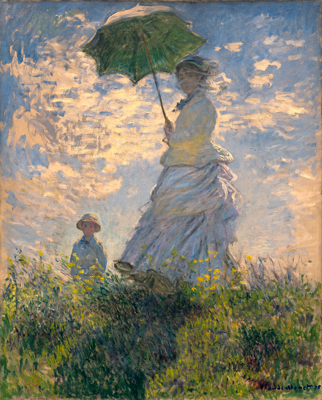

In [1]:
import io
from PIL import Image

import brushcue as bc

strength = 1.0
input_image = bc.Composition.monet_women_with_parasol()
bounds = input_image.bounds()
base_grade = input_image.l_curve(
    bc.Curve.s_curve(0.5, 1.08, 1.0, 1.0)
).saturation_adjust(0.98)
graded = base_grade.color_transformer_shader(
    "let shadow_weight = smoothstep(0.45, 0.08, input.r);\nlet highlight_weight = smoothstep(0.5, 0.86, input.r);\nlet a = input.g - 0.02 * shadow_weight + 0.035 * highlight_weight;\nlet b = input.b - 0.03 * shadow_weight + 0.055 * highlight_weight;\nreturn vec4f(input.r, a, b, input.a);",
    "",
    bc.ColorRepresentation.oklab_a(),
    bc.ColorRepresentation.oklab_a(),
    bc.Dictionary.create(),
)
filtered = graded.film_grain(1.1, 150.0, 0.5, 51.0, 0.3, 300.0, 0.14).crop(bounds)
graph = filtered.opacity_scales(strength).blend_alpha(input_image).crop(bounds)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
